# Freight Rate Prediction: full walkthrough



**Steps**
1. Load the data and get an overview
2. Data-quality issues and fixes
3. Key findings from exploration (distance, time trend, `quote_signal` regimes, unseen cities)
4. Cleaning and feature engineering
5. Models: lane-average baseline, Ridge, LightGBM with a linear trend
6. Validation: time-based holdout, new-city holdout, rolling monthly validation
7. Final model, predictions, December chart inputs and `score.py`

In [1]:
import inspect
import os
import subprocess
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from src import clean, config, eda
from src.features import LaneEncoder, build_base_features, category_levels, haversine_miles, quote_regimes
from src.models import LaneAverageBaseline, LightGBMModel, ModelContext, RidgeModel
from src.validate import error_breakdown, evaluate_split, holdout_split, new_city_holdout, rolling_cv

Path("outputs/figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def show(obj):
    """Print the source of a function or class from src/."""
    display(Markdown(f"```python\n{inspect.getsource(obj)}\n```"))

## 1. Load the data

In [2]:
train_raw, validation_raw, december_raw = clean.load_raw()
for name, frame in [("train_test", train_raw), ("validation", validation_raw), ("december_chart_inputs", december_raw)]:
    print(f"{name:22s} rows={len(frame):6,}  dates {frame['date'].min().date()} -> {frame['date'].max().date()}")
train_raw.head()

train_test             rows=48,000  dates 2025-01-01 -> 2025-10-31
validation             rows=12,000  dates 2025-11-01 -> 2025-12-31
december_chart_inputs  rows=    31  dates 2025-12-01 -> 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [3]:
train_raw.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.400000,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


**Note:** the labelled data runs from January to October 2025, while every load to predict is in November or December 2025.
Validation therefore has to be **time-based**: always train on the past and test on a later period.

## 2. Data-quality issues

In [4]:
missing = pd.DataFrame({
    "train_missing": train_raw.isna().sum(),
    "validation_missing": validation_raw.isna().sum(),
})
missing[missing.sum(axis=1) > 0]

,train_missing,validation_missing
market_index,374,249.0
weight,300,165.0


### 2a. Negative weights look like sign errors

In [5]:
negative = train_raw.loc[train_raw["weight"] < 0, "weight"].abs()
positive = train_raw.loc[train_raw["weight"] > 0, "weight"]
print(f"negative weights: train={len(negative)}, validation={(validation_raw['weight'] < 0).sum()}")
pd.DataFrame({"abs(negative weights)": negative.describe(), "positive weights": positive.describe()}).round(0)

negative weights: train=292, validation=145


,abs(negative weights),positive weights
count,292.0,47408.0
mean,31724.0,31415.0
std,8263.0,7995.0
min,5000.0,5000.0
25%,25928.0,25922.0
50%,31822.0,31494.0
75%,37284.0,37063.0
max,47500.0,47500.0


The absolute values of the negative weights have the same distribution as normal weights, so the fix is to take the absolute value.

### 2b. Label errors: some rates are roughly 3-4x too high or about 4x too low

In [6]:
show(clean.flag_label_outliers)

```python
def flag_label_outliers(frame: pd.DataFrame) -> pd.Series:
    """True for rows whose posted_rate looks like a data-entry error.

    The bad labels sit at roughly 4x or 0.25x the normal rate per mile for the
    same equipment and distance band, far outside the natural spread.
    """
    rate_per_mile = frame[config.TARGET] / frame["distance"]
    band = pd.cut(frame["distance"], DISTANCE_BANDS)
    expected = rate_per_mile.groupby([frame["equipment"], band], observed=True).transform("median")
    ratio = rate_per_mile / expected
    return (ratio > config.OUTLIER_HIGH_RATIO) | (ratio < config.OUTLIER_LOW_RATIO)

```

flagged label errors: 677 of 48,000 (1.41%)


too high: 340 rows, median 3.37x normal
too low:  337 rows, median 0.28x normal


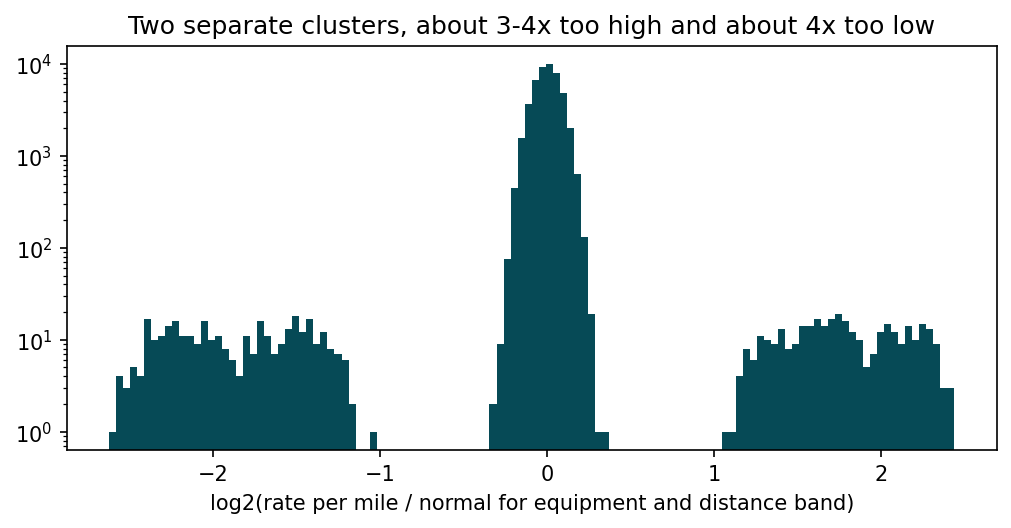

In [7]:
train_flags = train_raw.copy()
train_flags["label_outlier"] = clean.flag_label_outliers(train_flags)
rpm = train_flags[config.TARGET] / train_flags["distance"]
band = pd.cut(train_flags["distance"], clean.DISTANCE_BANDS)
ratio = rpm / rpm.groupby([train_flags["equipment"], band], observed=True).transform("median")
print(f"flagged label errors: {train_flags['label_outlier'].sum()} of {len(train_flags):,} ({train_flags['label_outlier'].mean():.2%})")
flagged = ratio[train_flags["label_outlier"]]
print(f"too high: {(flagged > 1).sum()} rows, median {flagged[flagged > 1].median():.2f}x normal")
print(f"too low:  {(flagged < 1).sum()} rows, median {flagged[flagged < 1].median():.2f}x normal")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log2(ratio), bins=120, color="#064A56")
ax.set_yscale("log"); ax.set_xlabel("log2(rate per mile / normal for equipment and distance band)")
ax.set_title("Two separate clusters, about 3-4x too high and about 4x too low")
fig.savefig("outputs/figures/label_error_ratios.png", dpi=150, bbox_inches="tight"); plt.close(fig)
display(Image("outputs/figures/label_error_ratios.png"))

### 2c. Distances are fine

In [8]:
straight = haversine_miles(train_raw["pickup_lat"], train_raw["pickup_lon"], train_raw["delivery_lat"], train_raw["delivery_lon"])
circuity = train_raw["distance"] / straight
print(circuity.describe().round(3).to_string())
high = train_raw[circuity > 1.5]
print(f"\nrows with distance > 1.5x straight line: {len(high)}, median distance {high['distance'].median():.0f} mi")
print(f"their median rate per mile: {(high[config.TARGET] / high['distance']).median():.2f} (normal short-haul range)")

count    48000.000
mean         1.195
std          0.144
min          1.058
25%          1.165
50%          1.182
75%          1.205
max          9.635

rows with distance > 1.5x straight line: 214, median distance 89 mi
their median rate per mile: 2.91 (normal short-haul range)


High road-to-straight-line ratios only occur on short routes, and their rate per mile is normal, so distance is left unchanged.

### 2d. Cities that never appear in training

In [9]:
train_cities = set(train_raw["pickup"]) | set(train_raw["delivery"])
validation_cities = set(validation_raw["pickup"]) | set(validation_raw["delivery"])
new_cities = sorted(validation_cities - train_cities)
touches_new = validation_raw["pickup"].isin(new_cities) | validation_raw["delivery"].isin(new_cities)
print("cities only in validation:", new_cities)
print(f"validation loads touching a new city: {touches_new.sum():,} ({touches_new.mean():.1%})")

cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation loads touching a new city: 1,447 (12.1%)


About 12% of the loads to predict involve a city the model has never seen, so cities are represented by coordinates
and by "city effects" that can be borrowed from the nearest known cities, not as category labels.

## 3. Key findings from exploration

In [10]:
daily_market = clean.build_daily_market(train_raw, validation_raw)
cities = clean.build_city_table(train_raw, validation_raw)
categories = category_levels(train_raw, validation_raw, december_raw)

cleaner = clean.FeatureCleaner().fit(train_raw)
train = cleaner.transform(train_raw, daily_market)
validation = cleaner.transform(validation_raw, daily_market)
train["label_outlier"] = clean.flag_label_outliers(train)
clean_train = train[~train["label_outlier"]].copy()
clean_train["rpm"] = clean_train[config.TARGET] / clean_train["distance"]
clean_train["log_rpm"] = np.log(clean_train["rpm"])

### 3a. Rate per mile falls with distance and depends on equipment

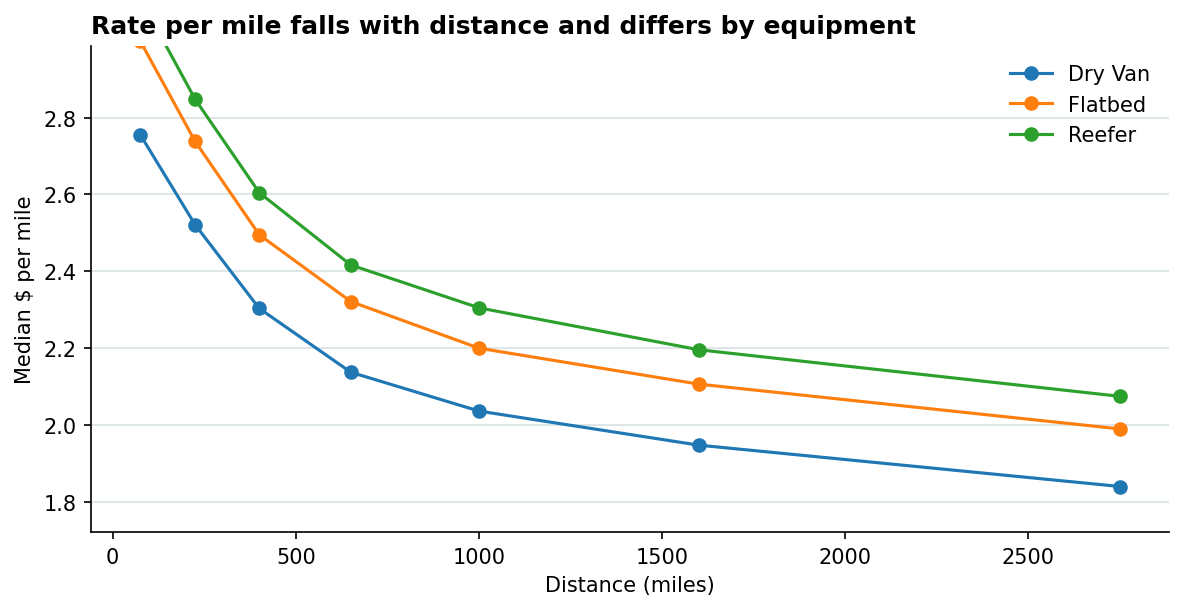

In [11]:
eda.rate_per_mile_by_distance(train, Path("outputs/figures/rate_per_mile_by_distance.png"))
display(Image("outputs/figures/rate_per_mile_by_distance.png"))
bands = pd.cut(clean_train["distance"], [0, 150, 300, 500, 800, 1200, 2000, 3500])
print("Median $ per mile by distance band (all equipment):")
print(clean_train.groupby(bands, observed=True)["rpm"].median().round(2).to_string())
print("\nMedian $ per mile by equipment:")
print(clean_train.groupby("equipment")["rpm"].median().round(2).to_string())

### 3b. Rates drift upward over time beyond what `market_index` explains

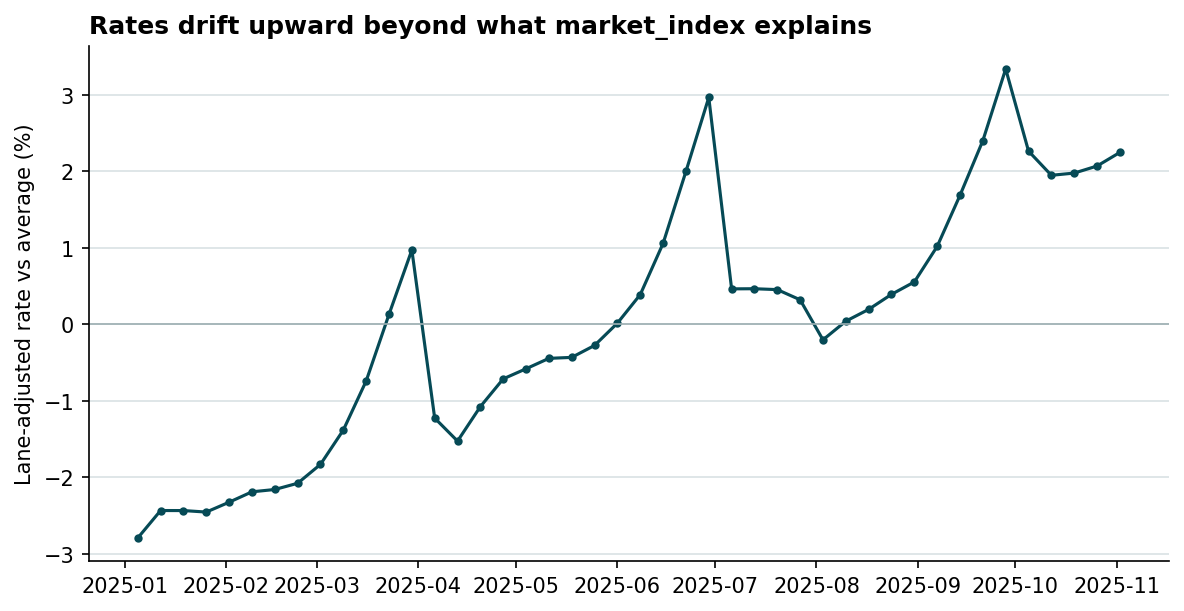

Lane-adjusted rate vs average, % (monthly mean of the weekly points):
date
2025-01   -2.53
2025-02   -2.19
2025-03   -0.57
2025-04   -1.14
2025-05   -0.44
2025-06    1.28
2025-07    0.42
2025-08    0.19
2025-09    2.11
2025-10    2.06
2025-11    2.24
Freq: M

Change from first to last month: +4.8 percentage points


In [12]:
weekly = eda.residual_trend(train, Path("outputs/figures/residual_trend.png"))
display(Image("outputs/figures/residual_trend.png"))
monthly = weekly.groupby(weekly.index.to_period("M")).mean().round(2)
print("Lane-adjusted rate vs average, % (monthly mean of the weekly points):")
print(monthly.to_string())
print(f"\nChange from first to last month: {monthly.iloc[-1] - monthly.iloc[0]:+.1f} percentage points")

After removing lane, market-index and weight effects, rates still rise about 4-5% from January to October.
Trees cannot extrapolate a trend past the last training date, so the final model fits a **linear trend first**
and lets LightGBM model what is left.

### 3c. `quote_signal` switches between three regimes

In [13]:
clean_train["log_quote"] = np.log(clean_train["quote_signal"])
rows = []
for month, group in clean_train.groupby(clean_train["date"].dt.month):
    slope, intercept = np.polyfit(group["log_rpm"], group["log_quote"], 1)
    rows.append({"month": month, "corr(log quote, log rate per mile)": group["log_quote"].corr(group["log_rpm"]),
                 "slope": slope})
pd.DataFrame(rows).round(3)

,month,"corr(log quote, log rate per mile)",slope
0,1,0.996,1.001
1,2,0.996,0.999
2,3,0.996,1.001
3,4,-0.977,-1.229
4,5,-0.975,-1.304
5,6,0.997,0.999
6,7,-0.974,-1.287
7,8,-0.019,-0.018
8,9,0.997,1.001
9,10,-0.972,-1.282


- **Jan, Feb, Mar, Jun, Sep:** the quote equals the true rate per mile (correlation about +0.996).
- **Apr, May, Jul, Oct:** the quote is an inverted copy of the rate (correlation about -0.975).
- **Aug:** the quote is pure noise.

Which regime applies to November and December? This can be answered **without labels**: for each day, correlate the
quotes with a quote-free model's expected rate.

In [14]:
show(quote_regimes)

```python
def quote_regimes(reference_loads: pd.DataFrame, expected_log_rpm: np.ndarray) -> pd.DataFrame:
    """Classify each day's quote_signal behaviour without using labels.

    Per day, correlate log(quote_signal) with a quote-free model's expected log rate
    per mile. quote_signal switches between three regimes: it tracks the rate
    (correlation ~ +0.97), mirrors it inversely (~ -0.95), or is unrelated noise (~ 0).
    """
    frame = pd.DataFrame({
        "date": reference_loads["date"].to_numpy(),
        "log_quote": np.log(reference_loads["quote_signal"].to_numpy()),
        "expected": expected_log_rpm,
    })
    correlation = frame.groupby("date")[["log_quote", "expected"]].corr().xs("log_quote", level=1)["expected"]
    regime = np.select([correlation > 0.5, correlation < -0.5], ["tracks rate", "inverted"], "noise")
    return pd.DataFrame({"correlation": correlation, "regime": regime})

```

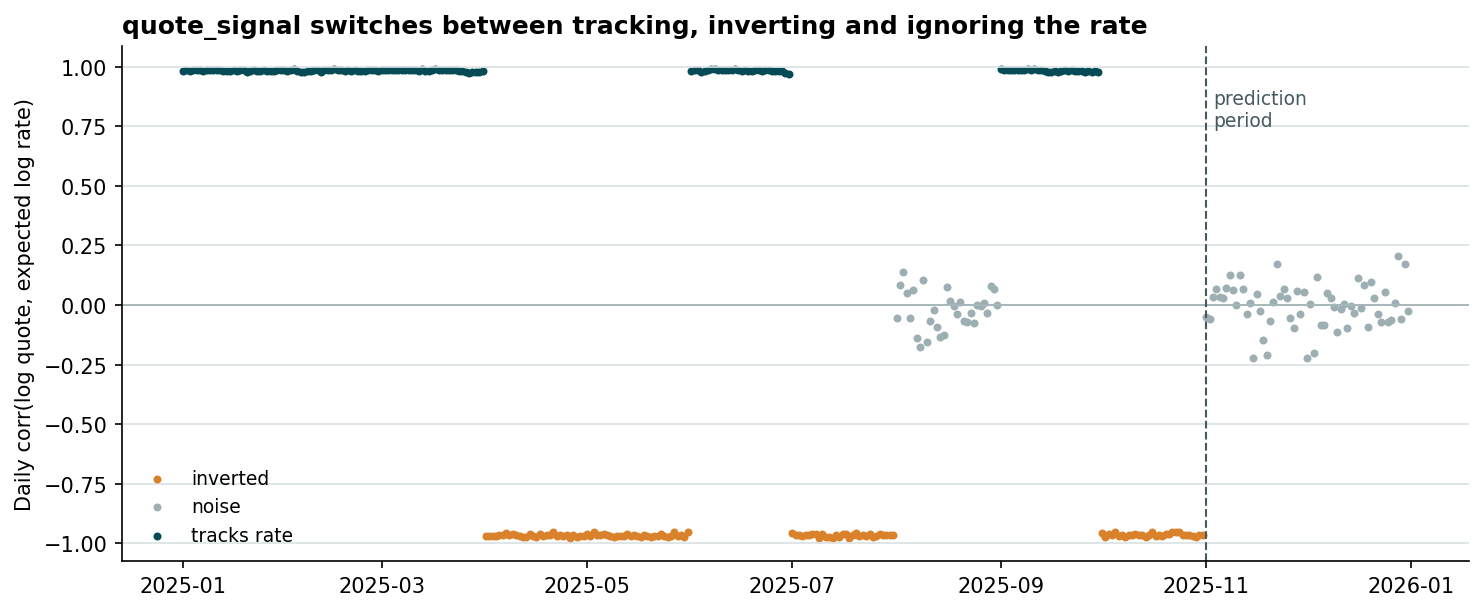

,mean_correlation,regime
date,,
2025-01,0.984,tracks rate
2025-02,0.984,tracks rate
2025-03,0.984,tracks rate
2025-04,-0.967,inverted
2025-05,-0.966,inverted
2025-06,0.983,tracks rate
2025-07,-0.966,inverted
2025-08,-0.021,noise
2025-09,0.984,tracks rate


In [15]:
reference_loads = pd.concat([train.drop(columns=[config.TARGET, "label_outlier"]), validation], ignore_index=True)
context = ModelContext(daily_market, categories, cities, reference_loads)

reference_model = RidgeModel(context).fit(train[~train["label_outlier"]])
regimes = quote_regimes(reference_loads, reference_model.predict_log_rpm(reference_loads))
eda.quote_regimes(regimes, Path("outputs/figures/quote_regimes.png"))
display(Image("outputs/figures/quote_regimes.png"))
regimes.groupby(regimes.index.to_period("M").astype(str)).agg(
    mean_correlation=("correlation", "mean"), regime=("regime", lambda r: r.mode()[0])).round(3)

**Every day in November and December is in the noise regime.** `quote_signal` carries no information about the rates we
must predict, so the models do **not** use it. A model that relied on it would look excellent on Jan-Oct validation
and then fail on the prediction period.

## 4. Cleaning and feature engineering

In [16]:
show(clean.FeatureCleaner)

```python
@dataclass
class FeatureCleaner:
    """Fixes input-feature quality issues. Fitted on training rows only."""

    weight_medians: dict[str, float] = field(default_factory=dict)
    overall_weight_median: float = 0.0

    def fit(self, frame: pd.DataFrame) -> "FeatureCleaner":
        weight = frame["weight"].abs()
        self.weight_medians = weight.groupby(frame["equipment"]).median().to_dict()
        self.overall_weight_median = float(weight.median())
        return self

    def transform(self, frame: pd.DataFrame, daily_market: pd.DataFrame) -> pd.DataFrame:
        result = frame.copy()

        result["weight_was_negative"] = (result["weight"] < 0).astype(int)
        result["weight_was_missing"] = result["weight"].isna().astype(int)
        result["weight"] = result["weight"].abs()
        fallback = result["equipment"].map(self.weight_medians).fillna(self.overall_weight_median)
        result["weight"] = result["weight"].fillna(fallback)

        result["market_index_was_missing"] = result["market_index"].isna().astype(int)
        day_average = result["date"].map(daily_market["daily_market_index"])
        result["market_index"] = result["market_index"].fillna(day_average)
        return result

```

In [17]:
show(clean.build_daily_market)

```python
def build_daily_market(*frames: pd.DataFrame) -> pd.DataFrame:
    """Daily average market_index across all loads posted that day.

    Uses only input features (never labels), so validation rows can contribute.
    Gaps in the calendar are filled by time interpolation.
    """
    combined = pd.concat([frame[["date", "market_index"]] for frame in frames])
    daily = combined.groupby("date").agg(
        daily_market_index=("market_index", "mean"),
        daily_load_count=("market_index", "size"),
    )
    calendar = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    daily = daily.reindex(calendar).interpolate(method="time").ffill().bfill()
    daily.index.name = "date"
    daily["market_index_7d"] = daily["daily_market_index"].rolling(7, min_periods=1).mean()
    daily["market_index_28d"] = daily["daily_market_index"].rolling(28, min_periods=1).mean()
    daily["market_momentum"] = daily["market_index_7d"] - daily["market_index_28d"]
    return daily

```

**Lane and city effects.** Each lane, pickup city and delivery city gets a smoothed average of how much more or less
it pays than a distance-and-equipment price curve. Training rows get out-of-fold values so a row never sees its own label.
New cities borrow the effect of their three nearest known cities.

In [18]:
show(LaneEncoder)

```python
@dataclass
class LaneEncoder:
    """How much more or less each lane, pickup city and delivery city pays than the
    distance curve predicts (smoothed average residual of log rate per mile).

    A city that never appears in training borrows the inverse-distance-weighted
    average of its nearest known cities; an unseen lane falls back to the sum of its
    pickup and delivery effects. Training rows get out-of-fold values so a row never
    sees its own label.
    """

    cities: pd.DataFrame
    smoothing: float = 20.0
    n_splits: int = 5
    neighbours: int = 3
    tables: dict[str, pd.Series] = field(default_factory=dict)

    def _fit_tables(self, frame: pd.DataFrame, residual: pd.Series) -> dict[str, pd.Series]:
        keys = {"lane": _lane_key(frame), "pickup": frame["pickup"], "delivery": frame["delivery"]}
        tables = {}
        for name, key in keys.items():
            stats = residual.groupby(key).agg(["sum", "count"])
            tables[name] = stats["sum"] / (stats["count"] + self.smoothing)
        return tables

    def _city_effect(self, cities: pd.Series, table: pd.Series) -> np.ndarray:
        effect = cities.map(table)
        unseen = sorted(set(cities[effect.isna()]))
        if unseen:
            known = self.cities.loc[table.index]
            borrowed = {}
            for city in unseen:
                lat, lon = self.cities.loc[city, ["lat", "lon"]]
                miles = haversine_miles(lat, lon, known["lat"].to_numpy(), known["lon"].to_numpy())
                nearest = np.argsort(miles)[: self.neighbours]
                weights = 1.0 / np.maximum(miles[nearest], 1.0)
                borrowed[city] = float(np.average(table.to_numpy()[nearest], weights=weights))
            effect = effect.fillna(cities.map(borrowed))
        return effect.to_numpy()

    def _apply(self, frame: pd.DataFrame, curve: np.ndarray, tables: dict[str, pd.Series]) -> pd.DataFrame:
        encoded = pd.DataFrame(index=frame.index)
        encoded["curve_log_rpm"] = curve
        encoded["pickup_effect"] = self._city_effect(frame["pickup"], tables["pickup"])
        encoded["delivery_effect"] = self._city_effect(frame["delivery"], tables["delivery"])
        lane = _lane_key(frame).map(tables["lane"])
        encoded["lane_effect"] = lane.fillna(encoded["pickup_effect"] + encoded["delivery_effect"])
        encoded["lane_log_rpm"] = encoded["curve_log_rpm"] + encoded["lane_effect"]
        return encoded

    def fit_transform(self, frame: pd.DataFrame, target: pd.Series) -> pd.DataFrame:
        self.curve = DistanceCurve().fit(frame, target)
        curve = self.curve.predict(frame)
        residual = target - curve
        self.tables = self._fit_tables(frame, residual)
        parts = []
        folds = KFold(self.n_splits, shuffle=True, random_state=config.RANDOM_SEED)
        for fit_idx, apply_idx in folds.split(frame):
            tables = self._fit_tables(frame.iloc[fit_idx], residual.iloc[fit_idx])
            parts.append(self._apply(frame.iloc[apply_idx], curve[apply_idx], tables))
        return pd.concat(parts).loc[frame.index]

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        return self._apply(frame, self.curve.predict(frame), self.tables)

```

In [19]:
show(build_base_features)

```python
def build_base_features(
    frame: pd.DataFrame, daily_market: pd.DataFrame, categories: dict[str, list[str]]
) -> pd.DataFrame:
    features = pd.DataFrame(index=frame.index)

    features["distance"] = frame["distance"]
    features["log_distance"] = np.log(frame["distance"])
    straight_line = haversine_miles(
        frame["pickup_lat"], frame["pickup_lon"], frame["delivery_lat"], frame["delivery_lon"]
    )
    features["straight_line_miles"] = straight_line
    features["circuity"] = frame["distance"] / np.maximum(straight_line, 1.0)

    for column in ("pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"):
        features[column] = frame[column]
    features["delta_lat"] = frame["delivery_lat"] - frame["pickup_lat"]
    features["delta_lon"] = frame["delivery_lon"] - frame["pickup_lon"]

    features["weight"] = frame["weight"]
    features["log_weight"] = np.log(frame["weight"])
    features["weight_was_negative"] = frame.get("weight_was_negative", 0)

    features["market_index"] = frame["market_index"]
    daily = daily_market.reindex(frame["date"]).set_index(frame.index)
    for column in ("daily_market_index", "market_index_7d", "market_index_28d", "market_momentum"):
        features[column] = daily[column]
    features["market_index_vs_day"] = frame["market_index"] - daily["daily_market_index"]

    features["days_since_start"] = (frame["date"] - TREND_ORIGIN).dt.days
    features["day_of_week"] = frame["date"].dt.dayofweek
    features["day_of_month"] = frame["date"].dt.day
    for column in CATEGORICAL_FEATURES:
        features[column] = pd.Categorical(frame[column], categories=categories[column])
    return features

```

In [20]:
encoder = LaneEncoder(cities)
lanes = encoder.fit_transform(clean_train, np.log(clean_train["rpm"]))
example = pd.concat([build_base_features(clean_train, daily_market, categories), lanes], axis=1)
print(f"{example.shape[1]} features")
example.head()

28 features


,distance,log_distance,straight_line_miles,circuity,pickup_lat,pickup_lon,delivery_lat,delivery_lon,delta_lat,delta_lon,weight,log_weight,weight_was_negative,market_index,daily_market_index,market_index_7d,market_index_28d,market_momentum,market_index_vs_day,days_since_start,day_of_week,day_of_month,equipment,curve_log_rpm,pickup_effect,delivery_effect,lane_effect,lane_log_rpm
0,274.3,5.614222,219.808768,1.247903,38.09122,-76.78906,38.16908,-72.74564,0.07786,4.04342,30658.0,10.330649,0,0.95684,0.961224,0.961224,0.961224,0.0,-0.004384,0,2,1,Dry Van,0.885839,-0.016617,-0.007164,-0.002237,0.883603
1,280.5,5.636574,220.525617,1.271961,38.09122,-76.78906,39.22317,-72.96710,1.13195,3.82196,17555.0,9.773094,0,0.97623,0.961224,0.961224,0.961224,0.0,0.015006,0,2,1,Reefer,1.004624,-0.017080,-0.018213,-0.030139,0.974485
2,967.8,6.875025,826.919847,1.170367,39.22317,-72.96710,44.30296,-87.52871,5.07979,-14.56161,31721.0,10.364734,0,1.00971,0.961224,0.961224,0.961224,0.0,0.048486,0,2,1,Dry Van,0.715056,-0.018979,-0.023401,-0.008994,0.706062
3,965.4,6.872543,840.540749,1.148546,39.55328,-72.18051,34.84933,-86.28940,-4.70395,-14.10889,32333.0,10.383844,0,0.94518,0.961224,0.961224,0.961224,0.0,-0.016044,0,2,1,Dry Van,0.715362,-0.015850,0.004010,-0.021397,0.693964
4,541.9,6.295081,434.163187,1.248148,31.83025,-94.38343,35.29479,-88.08915,3.46454,6.29428,35183.0,10.468318,0,0.98480,0.961224,0.961224,0.961224,0.0,0.023576,0,2,1,Reefer,0.912066,0.026592,0.009757,0.006512,0.918578


## 5. Models

All models predict **log(rate per mile)** and convert back to dollars. This keeps short and long loads on the same scale
and makes errors roughly proportional.

- **Baseline:** median rate per mile for the lane and equipment (falling back to an equipment and distance band) times distance.
- **Ridge regression:** a linear model on all features.
- **LightGBM + linear trend (final):** a linear model on time, market index, weight, distance and equipment captures the
  trend and can extrapolate it; gradient-boosted trees then model the remaining non-linear effects. Day-level features are
  kept out of the trees, because a value that is shared by every load on a day acts like a date ID and lets the trees
  memorise training days.

In [21]:
show(LaneAverageBaseline)

```python
class LaneAverageBaseline(RateModel):
    """Median rate per mile of the lane (or equipment x distance band) times distance."""

    name = "Baseline: lane average"

    def fit(self, frame: pd.DataFrame) -> "LaneAverageBaseline":
        target = log_rate_per_mile(frame)
        self.lane = target.groupby([frame["pickup"], frame["delivery"], frame["equipment"]]).median()
        self.band = target.groupby([frame["equipment"], self._band(frame)], observed=True).median()
        return self

    @staticmethod
    def _band(frame: pd.DataFrame) -> pd.Series:
        return pd.cut(frame["distance"], DISTANCE_BANDS)

    def predict_log_rpm(self, frame: pd.DataFrame) -> np.ndarray:
        lane_keys = pd.MultiIndex.from_frame(frame[["pickup", "delivery", "equipment"]])
        band_keys = pd.MultiIndex.from_arrays([frame["equipment"], self._band(frame)])
        lane = pd.Series(self.lane.reindex(lane_keys).to_numpy())
        band = pd.Series(self.band.reindex(band_keys).to_numpy())
        return lane.fillna(band).to_numpy()

```

In [22]:
show(LightGBMModel)

```python
class LightGBMModel(FeatureModel):
    """Gradient-boosted trees on log rate per mile.

    trend="linear" first fits a linear model with a time trend, so the slow upward
    drift in rates can be extrapolated past the last training date (trees alone
    would flatten it); the trees then learn what the linear model leaves over.
    """

    name = "LightGBM"

    def __init__(self, context: ModelContext, params: dict | None = None, trend: str | None = "linear",
                 drop_day_level: bool = True):
        super().__init__(context)
        self.params = {**LGBM_PARAMS, **(params or {})}
        self.trend = trend
        self.drop_day_level = drop_day_level

    def _trend_matrix(self, features: pd.DataFrame) -> pd.DataFrame:
        matrix = features[TREND_FEATURES].copy()
        for level in self.context.categories["equipment"]:
            matrix[f"equipment_{level}"] = (features["equipment"] == level).astype(float)
        return matrix

    def _tree_features(self, features: pd.DataFrame) -> pd.DataFrame:
        drop = [] if self.trend == "feature" else ["days_since_start"]
        if self.drop_day_level:
            drop += DAY_LEVEL_FEATURES
        if self.trend == "ridge":
            drop += ["market_index"]
        return features.drop(columns=drop)

    def _first_stage(self, features: pd.DataFrame) -> np.ndarray:
        if self.trend == "linear":
            return self.trend_model.predict(self._trend_matrix(features))
        if self.trend == "ridge":
            return self.trend_model.predict(features)
        return np.zeros(len(features))

    def _fit_estimator(self, features: pd.DataFrame, target: pd.Series) -> None:
        if self.trend == "linear":
            self.trend_model = LinearRegression().fit(self._trend_matrix(features), target)
        elif self.trend == "ridge":
            self.trend_model = fit_ridge(features, target)
        residual = target - self._first_stage(features)
        self.estimator = lgb.LGBMRegressor(**self.params)
        self.estimator.fit(self._tree_features(features), residual, categorical_feature=CATEGORICAL_FEATURES)

    def _predict_estimator(self, features: pd.DataFrame) -> np.ndarray:
        return self.estimator.predict(self._tree_features(features)) + self._first_stage(features)

    def trend_per_month(self) -> float:
        """Rate change per 30 days implied by the first-stage time coefficient, as a fraction."""
        if self.trend == "ridge":
            transformer, ridge = self.trend_model[0], self.trend_model[-1]
            names = list(transformer.get_feature_names_out())
            scale = transformer.named_transformers_["numeric"].scale_
            numeric = list(transformer.named_transformers_["numeric"].feature_names_in_)
            coefficient = ridge.coef_[names.index("numeric__days_since_start")] / scale[numeric.index("days_since_start")]
        else:
            coefficient = self.trend_model.coef_[TREND_FEATURES.index("days_since_start")]
        return float(np.exp(coefficient * 30) - 1)

    def feature_importance(self) -> pd.Series:
        gain = self.estimator.booster_.feature_importance(importance_type="gain")
        names = self.estimator.booster_.feature_name()
        return pd.Series(gain, index=names).sort_values(ascending=False) / gain.sum()

```

## 6. Validation

Three complementary checks, all time-based (never a random split):

1. **Holdout:** train on Jan-Aug, test on Sep-Oct, which mirrors predicting the next two months.
2. **New-city holdout:** same time split, but 8 random cities are removed from training entirely, which mirrors the
   validation set's unseen cities.
3. **Rolling monthly validation:** for each month from June to October, train on all earlier months and test on that month.

The 677 flagged label errors are excluded from training. Metrics are reported on clean test labels, and also on all labels for the holdout.

In [23]:
factories = {
    "Baseline: lane average": lambda: LaneAverageBaseline(context),
    "Ridge regression": lambda: RidgeModel(context),
    "LightGBM + linear trend": lambda: LightGBMModel(context),
}
fit_part, holdout = holdout_split(train)
rows_holdout, holdout_predictions = [], {}
for name, factory in factories.items():
    _, predicted, all_rows, clean_rows = evaluate_split(factory, fit_part, holdout)
    holdout_predictions[name] = predicted
    rows_holdout.append({"model": name, "rows": "clean labels", **clean_rows})
    rows_holdout.append({"model": name, "rows": "all labels", **all_rows})
pd.DataFrame(rows_holdout).round(3)

,model,rows,MAE,RMSE,MAPE_%,R2
0,Baseline: lane average,clean labels,82.156,120.104,3.453,0.992
1,Baseline: lane average,all labels,137.773,640.326,5.959,0.824
2,Ridge regression,clean labels,62.672,87.913,2.682,0.996
3,Ridge regression,all labels,118.434,636.694,5.148,0.826
4,LightGBM + linear trend,clean labels,47.795,73.115,1.985,0.997
5,LightGBM + linear trend,all labels,103.721,633.165,4.481,0.828


In [24]:
seen_lanes = set(zip(fit_part["pickup"], fit_part["delivery"]))
error_breakdown(holdout, holdout_predictions["LightGBM + linear trend"], seen_lanes)

,rows,MAE,MAPE_pct
equipment: Dry Van,5275,37.82,1.67
equipment: Flatbed,1746,69.25,2.78
equipment: Reefer,2358,54.21,2.10
distance band: <300 mi,770,11.63,2.07
distance band: 300-800 mi,3075,24.96,1.94
distance band: 800-1500 mi,2872,47.01,2.00
distance band: >1500 mi,2662,85.49,1.99
lane seen in training: seen,9358,47.79,1.98
lane seen in training: unseen,21,48.17,2.00


In [25]:
rows_city = []
for name, factory in factories.items():
    held, results = new_city_holdout(factory, train)
    for group, metrics in results.items():
        rows_city.append({"model": name, "rows": group, **metrics})
print("held-out cities:", ", ".join(held))
pd.DataFrame(rows_city).round(3)

held-out cities: Bakersfield, Hartford, Memphis, New York, San Antonio, Toledo, Tulsa, Washington


,model,rows,MAE,RMSE,MAPE_%,R2
0,Baseline: lane average,loads touching a new city,86.922,118.330,3.791,0.993
1,Baseline: lane average,loads between known cities,82.229,121.015,3.477,0.992
2,Ridge regression,loads touching a new city,69.280,100.238,2.815,0.995
3,Ridge regression,loads between known cities,61.788,86.508,2.684,0.996
4,LightGBM + linear trend,loads touching a new city,56.898,87.015,2.223,0.996
5,LightGBM + linear trend,loads between known cities,47.696,72.670,2.013,0.997


Rolling monthly validation takes a few minutes.

In [26]:
rolling = []
for name, factory in factories.items():
    table = rolling_cv(factory, train)
    table.insert(0, "model", name)
    rolling.append(table)
rolling = pd.concat(rolling).round(3)
display(rolling.pivot(index="test_month", columns="model", values="MAPE_%"))
rolling.groupby("model")[["MAE", "RMSE", "MAPE_%", "R2"]].mean().round(3)

model,Baseline: lane average,LightGBM + linear trend,Ridge regression
test_month,,,
2025-06,6.132,2.108,2.015
2025-07,4.067,3.212,4.846
2025-08,3.532,1.742,1.440
2025-09,3.483,2.420,3.051
2025-10,3.339,1.370,1.667


,MAE,RMSE,MAPE_%,R2
model,,,,
Baseline: lane average,99.224,141.072,4.111,0.989
LightGBM + linear trend,51.672,74.486,2.170,0.997
Ridge regression,61.588,86.109,2.604,0.995


**Choice:** LightGBM + linear trend has the lowest error on the Sep-Oct holdout, on loads touching unseen cities,
and on average across the rolling months. Ridge wins June and August but swings much more from month to month
(1.44% to 4.85%), so LightGBM is the more reliable choice.

## 7. Final model and predictions

In [27]:
final_training_rows = train[~train["label_outlier"]]
final_model = LightGBMModel(context).fit(final_training_rows)
print(f"final model trained on {len(final_training_rows):,} clean rows (Jan-Oct 2025)")
print(f"fitted time trend: {final_model.trend_per_month() * 100:+.2f}% per month")
final_model.feature_importance().head(15).round(4)

final model trained on 47,323 clean rows (Jan-Oct 2025)
fitted time trend: +0.63% per month


lane_effect            0.4711
pickup_effect          0.0728
weight                 0.0683
delivery_effect        0.0584
straight_line_miles    0.0489
market_index           0.0451
distance               0.0300
delivery_lat           0.0287
delivery_lon           0.0259
pickup_lat             0.0217
pickup_lon             0.0166
delta_lat              0.0164
log_weight             0.0149
circuity               0.0147
delta_lon              0.0144
dtype: float64

In [28]:
validation_rates = pd.Series(final_model.predict(validation), index=validation["load_id"])
template = pd.read_csv(config.TEMPLATE_PATH)
template["predicted_rate"] = template["load_id"].map(validation_rates).round(2)
assert template["predicted_rate"].notna().all() and (template["predicted_rate"] > 0).all()
template[["load_id", "predicted_rate"]].to_csv(config.PREDICTIONS_PATH, index=False)
print(f"wrote {len(template):,} rows to {config.PREDICTIONS_PATH.name}")
template["predicted_rate"].describe().round(2)

wrote 12,000 rows to validation_predictions.csv


count    12000.00
mean      2387.23
std       1372.13
min        196.06
25%       1290.92
50%       2064.56
75%       3394.67
max       6945.57
Name: predicted_rate, dtype: float64

**December chart inputs.** The file only has route, distance, equipment, weight and date. Coordinates come from the
city table, and `market_index` for each day is the average over that day's validation loads, so only the date changes.

In [29]:
show(clean.complete_december_inputs)

```python
def complete_december_inputs(
    december: pd.DataFrame, cities: pd.DataFrame, daily_market: pd.DataFrame
) -> pd.DataFrame:
    """Add the columns the model needs but the December chart file does not provide."""
    result = december.copy()
    for side in ("pickup", "delivery"):
        result[f"{side}_lat"] = result[side].map(cities["lat"])
        result[f"{side}_lon"] = result[side].map(cities["lon"])
    result["market_index"] = result["date"].map(daily_market["daily_market_index"])
    if result[["pickup_lat", "delivery_lat", "market_index"]].isna().any().any():
        raise ValueError("December inputs reference a city or date with no reference data")
    return result

```

In [30]:
december_original = pd.read_csv(config.DECEMBER_PATH)
december = cleaner.transform(clean.complete_december_inputs(december_raw, cities, daily_market), daily_market)
december_original["predicted_rate"] = np.round(final_model.predict(december), 2)
december_original.to_csv(config.DECEMBER_PATH, index=False)

rates = december_original["predicted_rate"]
print(f"December predictions: min ${rates.min():.2f}, max ${rates.max():.2f}, mean ${rates.mean():.2f} "
      f"(${rates.mean() / 360:.2f} per mile)")
print(f"correlation with daily market_index: {np.corrcoef(rates, december['market_index'])[0, 1]:.2f}")
history = train_raw[(train_raw["pickup"] == "Lexington") & (train_raw["delivery"] == "Fort Wayne")
                    & (train_raw["equipment"] == "Dry Van")]
print(f"history, same lane Dry Van: {len(history)} loads, median ${history[config.TARGET].median():.2f}")
print(history[history["date"].dt.month == 10][["date", "weight", config.TARGET]].to_string(index=False))
december_original.assign(market_index=december["market_index"].round(3).to_numpy())

December predictions: min $838.34, max $862.68, mean $851.35 ($2.36 per mile)
correlation with daily market_index: 0.98
history, same lane Dry Van: 21 loads, median $807.89
      date  weight  posted_rate
2025-10-01 26829.0       841.42
2025-10-26 17917.0       796.48
2025-10-30 26358.0       864.61


,pickup,delivery,distance,equipment,weight,date,predicted_rate,market_index
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,841.08,0.835
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,847.20,0.915
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,855.52,0.994
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,857.03,1.024
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,854.71,0.975
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,846.52,0.889
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,838.34,0.831
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,842.52,0.840
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,847.59,0.917
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,856.74,0.999


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.



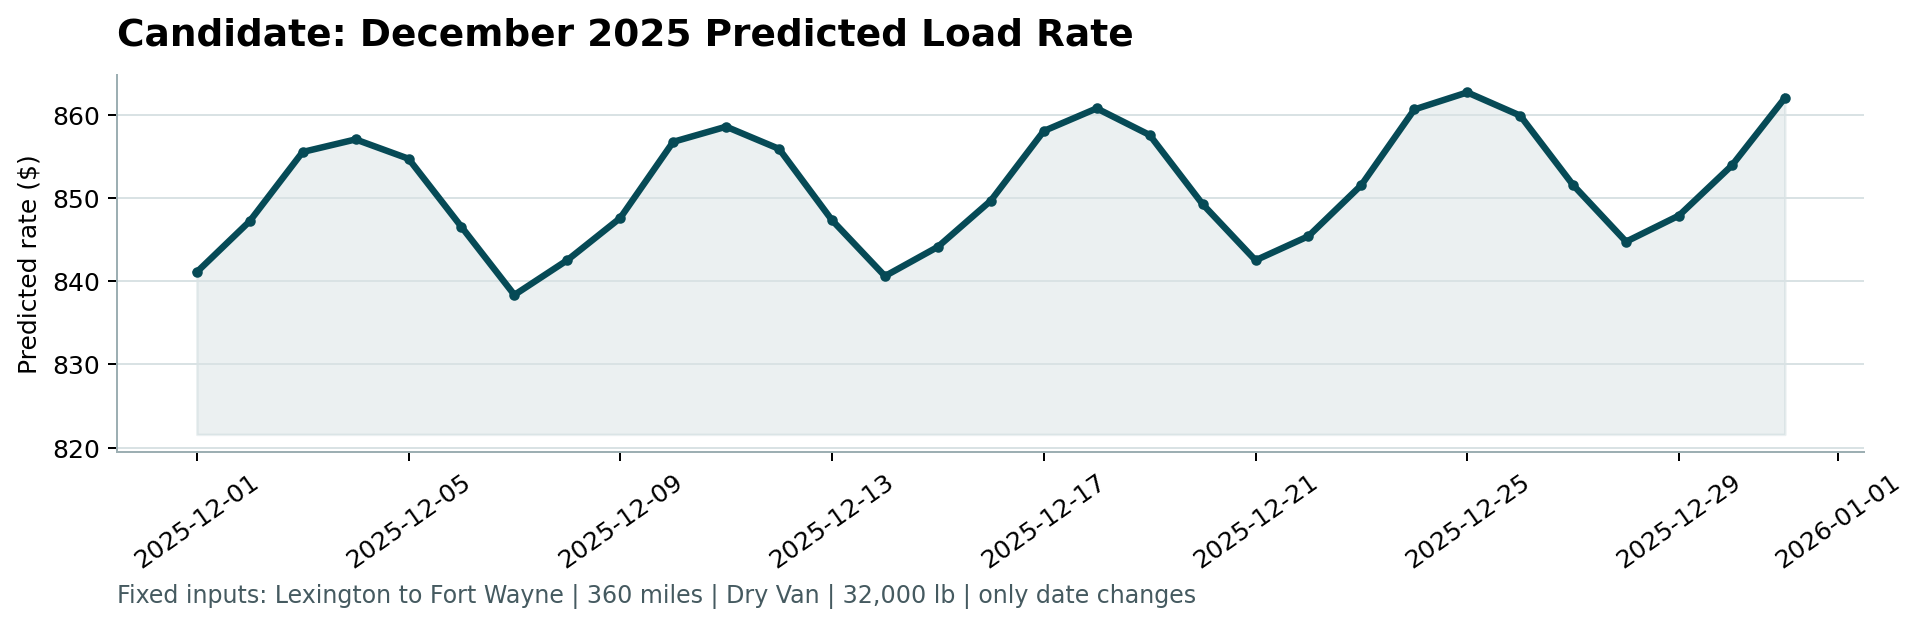

In [31]:
result = subprocess.run(
    [sys.executable, "score.py", "--predictions", "validation_predictions.csv",
     "--december-predictions", "data/december_chart_inputs.csv"],
    capture_output=True, text=True,
)
print(result.stdout or result.stderr)
display(Image("scorer_results/candidate_december.png"))

## 8. Key numbers (summary for the report )

Every number quoted in `report/REPORT.md` and the walkthrough, computed from the variables above.

In [32]:
holdout_table = pd.DataFrame(rows_holdout)
city_table = pd.DataFrame(rows_city)
rolling_mape = rolling.pivot(index="test_month", columns="model", values="MAPE_%")
lgbm = "LightGBM + linear trend"
holdout_mape = holdout_table[(holdout_table["model"] == lgbm) & (holdout_table["rows"] == "clean labels")]["MAPE_%"].iloc[0]
new_city_mape = city_table[(city_table["model"] == lgbm) & (city_table["rows"] == "loads touching a new city")]["MAPE_%"].iloc[0]

key_numbers = {
    "labelled loads": f"{len(train_raw):,} ({train_raw['date'].min().date()} to {train_raw['date'].max().date()})",
    "loads to predict": f"{len(validation_raw):,} ({validation_raw['date'].min().date()} to {validation_raw['date'].max().date()})",
    "label errors removed": f"{int(train['label_outlier'].sum())} ({train['label_outlier'].mean():.1%})",
    "negative weights": int((train_raw["weight"] < 0).sum()),
    "missing weights": int(train_raw["weight"].isna().sum()),
    "missing market_index": int(train_raw["market_index"].isna().sum()),
    "new cities in prediction set": f"{len(new_cities)} cities, {touches_new.sum():,} loads ({touches_new.mean():.0%})",
    "Nov-Dec quote regime": ", ".join(sorted(set(regimes.loc[validation["date"].unique(), "regime"]))),
    "fitted time trend": f"{final_model.trend_per_month() * 100:+.2f}% per month",
    "holdout MAPE (Sep-Oct)": f"{holdout_mape:.2f}%",
    "new-city MAPE": f"{new_city_mape:.2f}%",
    "rolling MAPE, LightGBM": f"{rolling_mape[lgbm].mean():.2f}%",
    "rolling MAPE, Ridge": f"{rolling_mape['Ridge regression'].mean():.2f}% "
                           f"(ranges {rolling_mape['Ridge regression'].min():.2f}% to {rolling_mape['Ridge regression'].max():.2f}%)",
    "rolling MAPE, baseline": f"{rolling_mape['Baseline: lane average'].mean():.2f}%",
    "final training rows": f"{len(final_training_rows):,}",
    "December prediction range": f"${rates.min():.2f} to ${rates.max():.2f}",
}
pd.Series(key_numbers, name="value").to_frame()

,value
labelled loads,"48,000 (2025-01-01 to 2025-10-31)"
loads to predict,"12,000 (2025-11-01 to 2025-12-31)"
label errors removed,677 (1.4%)
negative weights,292
missing weights,300
missing market_index,374
new cities in prediction set,"8 cities, 1,447 loads (12%)"
Nov-Dec quote regime,noise
fitted time trend,+0.63% per month
holdout MAPE (Sep-Oct),1.98%
